# Detecção de fraude em cartão de crédito

Desafio DIO. O objetivo é identificar transações fraudulentas em um conjunto de dados muito desbalanceado,
comparando três modelos que usam o **peso das classes** e ajustando o **limiar de decisão**.

Roteiro: **1. Explore → 2. Prepare → 3. Treine → 4. Avalie → 5. Explique**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 40)

## 1. Explore

O dataset é carregado direto da URL (nenhuma cópia é salva em disco).
As colunas `V1` a `V28` já vêm transformadas por PCA; `Time` e `Amount` estão na escala original; `Class = 1` indica fraude.

In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(URL)
df.shape

(284807, 31)

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.236957e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.771718e-16,1.037846e-15,6.418678e-16,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [6]:
proporcao = df["Class"].value_counts(normalize=True)
proporcao

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

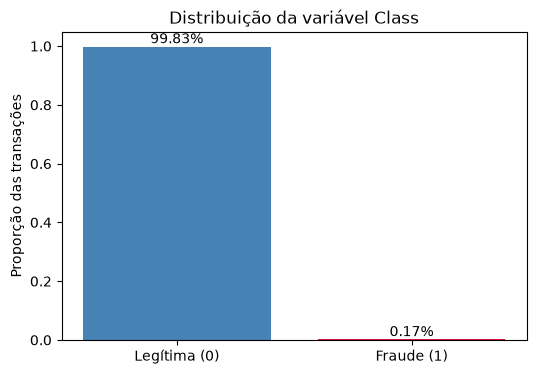

In [7]:
rotulos = proporcao.rename({0: "Legítima (0)", 1: "Fraude (1)"})
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(rotulos.index, rotulos.values, color=["steelblue", "crimson"])
ax.bar_label(barras, labels=[f"{v:.2%}" for v in rotulos.values])
ax.set_ylabel("Proporção das transações")
ax.set_title("Distribuição da variável Class")
plt.show()

**Conclusões da exploração**

- `shape`: o dataset tem **284.807 transações** e **31 colunas**.
- `info()`: todas as colunas são numéricas e têm 284.807 valores não nulos, ou seja, **não há valores ausentes**.
- `value_counts(normalize=True)`: **99,83%** das transações são legítimas e só **0,17%** são fraude. As classes são extremamente desbalanceadas.
- `describe()`:
  - `V1` a `V28` têm **média praticamente zero**.
  - `Amount` é **muito assimétrica**: mediana de 22,00, média de 88,35 e máximo de 25.691,16. Poucos valores muito altos puxam a média para cima.
  - `Time` vai de 0 a 172.792.

## 2. Prepare

- `log_amount = log(1 + Amount)` reduz a assimetria do valor da transação (poucos valores muito altos).
- Variáveis usadas: `Time`, `V1`–`V28` e `log_amount`.
- Divisão treino/teste **estratificada** (80/20), para manter a mesma proporção de fraude nos dois conjuntos.
- `StandardScaler` ajustado **só no treino** e depois aplicado ao teste, para não vazar informação do teste.

In [8]:
df["log_amount"] = np.log1p(df["Amount"])

features = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["log_amount"]
X = df[features]
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=features, index=X_test.index)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (227845, 30) | Teste: (56962, 30)


In [9]:
comparacao_split = pd.DataFrame({
    "Treino (qtde)": y_train.value_counts(),
    "Treino (proporção)": y_train.value_counts(normalize=True),
    "Teste (qtde)": y_test.value_counts(),
    "Teste (proporção)": y_test.value_counts(normalize=True),
}).rename(index={0: "Legítima", 1: "Fraude"})
comparacao_split

,Treino (qtde),Treino (proporção),Teste (qtde),Teste (proporção)
Class,,,,
Legítima,227451,0.998271,56864,0.99828
Fraude,394,0.001729,98,0.00172


**Conclusões da preparação**

- Treino com **227.845** transações (394 fraudes) e teste com **56.962** (98 fraudes).
- A estratificação funcionou: a fraude representa **0,1729%** do treino e **0,1720%** do teste.
- O teste tem só 98 fraudes, então cada fraude perdida ou encontrada move o recall em cerca de 1 ponto percentual.

## 3. Treine (usando o peso das classes)

Os três modelos dão **mais peso à classe fraude**:

- **Regressão logística** (baseline) com `class_weight="balanced"`;
- **Random Forest** com `class_weight="balanced"`;
- **XGBoost** com `scale_pos_weight = negativos / positivos` do conjunto de ajuste.

Para escolher o **limiar de decisão** sem olhar o teste, separamos uma **validação estratificada** a partir do treino
(20% do treino). Os modelos são ajustados no restante do treino e o limiar é escolhido na validação.

In [10]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

negativos, positivos = (y_fit == 0).sum(), (y_fit == 1).sum()
scale_pos_weight = negativos / positivos
print(f"Ajuste: {len(y_fit)} linhas ({positivos} fraudes) | Validação: {len(y_val)} linhas ({y_val.sum()} fraudes)")
print(f"scale_pos_weight = {negativos} / {positivos} = {scale_pos_weight:.1f}")

Ajuste: 182276 linhas (315 fraudes) | Validação: 45569 linhas (79 fraudes)
scale_pos_weight = 181961 / 315 = 577.7


In [11]:
modelos = {
    "Regressão logística": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric="aucpr"),
}

for nome, modelo in modelos.items():
    modelo.fit(X_fit, y_fit)
    print(f"{nome}: treinado")

Regressão logística: treinado


Random Forest: treinado


XGBoost: treinado


### Ajuste do limiar de decisão

Por padrão a classe prevista é fraude quando a probabilidade é ≥ 0,5. Aqui, para cada modelo, percorremos a
curva precisão-recall **da validação** e escolhemos o limiar que **maximiza o F1 da classe fraude**.
O conjunto de teste não participa desta escolha.

In [12]:
def limiar_max_f1(y_true, proba):
    precisao, recall, limiares_pr = precision_recall_curve(y_true, proba)
    f1 = 2 * precisao * recall / (precisao + recall + 1e-12)
    i = np.argmax(f1[:-1])  # o último ponto da curva não tem limiar associado
    return limiares_pr[i], f1[i]


limiares = {}
linhas_val = []
for nome, modelo in modelos.items():
    proba_val = modelo.predict_proba(X_val)[:, 1]
    limiar, f1_val = limiar_max_f1(y_val, proba_val)
    limiares[nome] = limiar
    linhas_val.append({"Modelo": nome, "Limiar escolhido": limiar, "F1 fraude (validação)": f1_val})

pd.DataFrame(linhas_val).round({"Limiar escolhido": 6, "F1 fraude (validação)": 4})

,Modelo,Limiar escolhido,F1 fraude (validação)
0,Regressão logística,1.00000,0.7692
1,Random Forest,0.41000,0.8378
2,XGBoost,0.92717,0.8493


**Conclusões do treino e do limiar**

- O conjunto de ajuste tem 182.276 linhas (315 fraudes), o que dá `scale_pos_weight ≈ 577,7` para o XGBoost.
- Limiares que maximizam o F1 na validação (45.569 linhas, 79 fraudes):
  - **Regressão logística: limiar de 0,99999994** (aparece arredondado como 1,0 na tabela). Isso quer dizer que a logística só classifica uma transação como fraude quando a probabilidade calculada é **praticamente 100%**. Na validação, esse corte foi o que deu o melhor equilíbrio entre pegar fraudes e evitar alarmes falsos (F1 de 0,7692). O efeito dele em comparação com o limiar 0,5 aparece na seção 4.
  - **Random Forest: limiar de 0,41**, um pouco abaixo de 0,5. Ele marca fraude com uma probabilidade menor do que o padrão, então tende a **pegar mais fraudes**, com o risco de mais alarmes falsos.
  - **XGBoost: limiar de 0,927**, bem acima de 0,5. Ele só marca fraude quando tem muita certeza, então tende a **ter menos alarmes falsos**, com o risco de deixar passar mais fraudes.
- Como a validação tem só 79 fraudes, o limiar escolhido é sensível a poucos casos. O teste vai mostrar se ele se sustenta.

## 4. Avalie (no teste)

Agora sim usamos o teste, que ficou separado desde o início. Cada modelo é avaliado com o limiar padrão (0,5)
e com o limiar ajustado na validação.

In [13]:
proba_teste = {nome: modelo.predict_proba(X_test)[:, 1] for nome, modelo in modelos.items()}

for nome, proba in proba_teste.items():
    for rotulo, limiar in [("limiar padrão 0,5", 0.5), (f"limiar ajustado {limiares[nome]:.6f}", limiares[nome])]:
        pred = (proba >= limiar).astype(int)
        print(f"===== {nome} | {rotulo} =====")
        print(classification_report(y_test, pred, target_names=["Legítima", "Fraude"], digits=4))

===== Regressão logística | limiar padrão 0,5 =====
              precision    recall  f1-score   support

    Legítima     0.9998    0.9760    0.9878     56864
      Fraude     0.0612    0.9082    0.1146        98

    accuracy                         0.9759     56962
   macro avg     0.5305    0.9421    0.5512     56962
weighted avg     0.9982    0.9759    0.9863     56962

===== Regressão logística | limiar ajustado 1.000000 =====
              precision    recall  f1-score   support

    Legítima     0.9997    0.9997    0.9997     56864
      Fraude     0.8316    0.8061    0.8187        98

    accuracy                         0.9994     56962
   macro avg     0.9156    0.9029    0.9092     56962
weighted avg     0.9994    0.9994    0.9994     56962

===== Random Forest | limiar padrão 0,5 =====
              precision    recall  f1-score   support

    Legítima     0.9997    0.9999    0.9998     56864
      Fraude     0.9101    0.8265    0.8663        98

    accuracy             

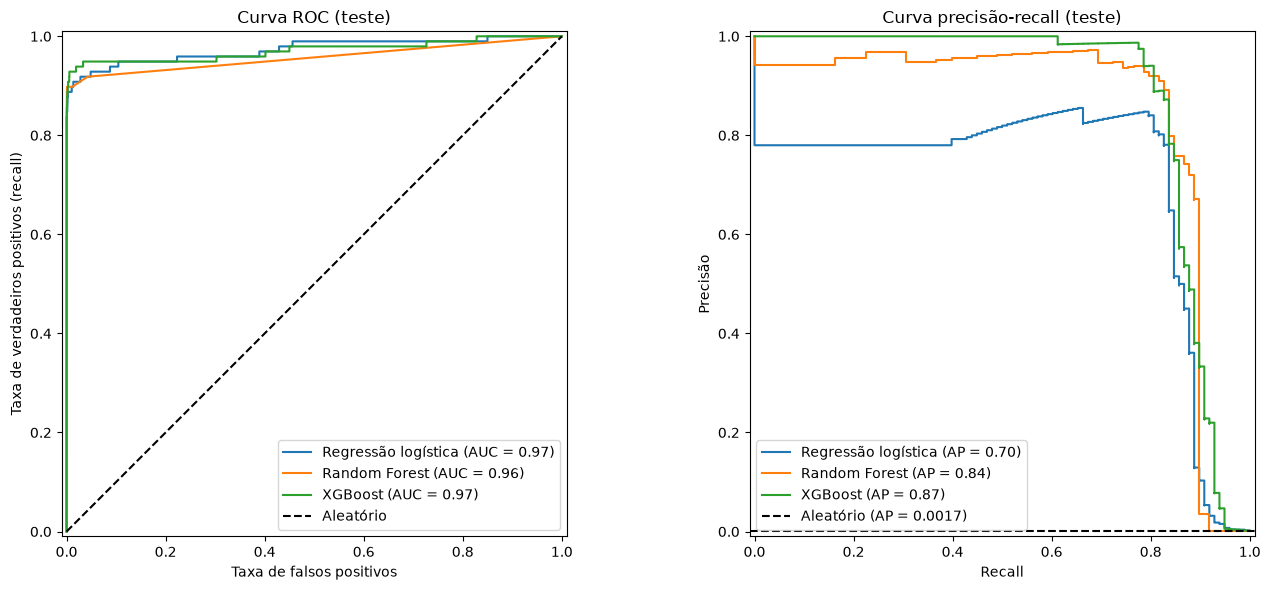

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for nome, proba in proba_teste.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=nome, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=nome, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="Aleatório")
axes[0].set_title("Curva ROC (teste)")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos (recall)")
axes[0].legend(loc="lower right")

axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"Aleatório (AP = {y_test.mean():.4f})")
axes[1].set_title("Curva precisão-recall (teste)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

### Tabela comparativa (classe fraude)

A métrica principal é o **recall da fraude**: a proporção das fraudes reais que o modelo consegue pegar.
Precisão e F1 aparecem ao lado porque recall alto com precisão muito baixa significa bloquear muitas transações legítimas.

In [15]:
linhas = []
for nome, proba in proba_teste.items():
    for rotulo, limiar in [("padrão (0,5)", 0.5), ("ajustado", limiares[nome])]:
        pred = (proba >= limiar).astype(int)
        linhas.append({
            "Modelo": nome,
            "Limiar": rotulo,
            "Valor do limiar": limiar,
            "Recall (fraude)": recall_score(y_test, pred),
            "Precisão (fraude)": precision_score(y_test, pred, zero_division=0),
            "F1 (fraude)": f1_score(y_test, pred),
        })

tabela = pd.DataFrame(linhas).sort_values("Recall (fraude)", ascending=False).reset_index(drop=True)
tabela.round({"Valor do limiar": 6, "Recall (fraude)": 4, "Precisão (fraude)": 4, "F1 (fraude)": 4})

,Modelo,Limiar,Valor do limiar,Recall (fraude),Precisão (fraude),F1 (fraude)
0,Regressão logística,"padrão (0,5)",0.50000,0.9082,0.0612,0.1146
1,Random Forest,ajustado,0.41000,0.8367,0.8913,0.8632
2,XGBoost,"padrão (0,5)",0.50000,0.8265,0.8710,0.8482
3,Random Forest,"padrão (0,5)",0.50000,0.8265,0.9101,0.8663
4,Regressão logística,ajustado,1.00000,0.8061,0.8316,0.8187
5,XGBoost,ajustado,0.92717,0.7959,0.9398,0.8619


### Escolha do modelo

O modelo escolhido é o de **maior recall da fraude com o limiar ajustado** (desempate pelo F1).
Usamos o limiar ajustado porque o limiar 0,5 pode dar recall alto à custa de uma precisão inviável,
como acontece com a regressão logística.

In [16]:
ajustados = tabela[tabela["Limiar"] == "ajustado"].sort_values(
    ["Recall (fraude)", "F1 (fraude)"], ascending=False
)
modelo_escolhido = ajustados.iloc[0]["Modelo"]
limiar_escolhido = limiares[modelo_escolhido]
print(f"Modelo escolhido: {modelo_escolhido} | limiar = {limiar_escolhido:.6f}")

Modelo escolhido: Random Forest | limiar = 0.410000


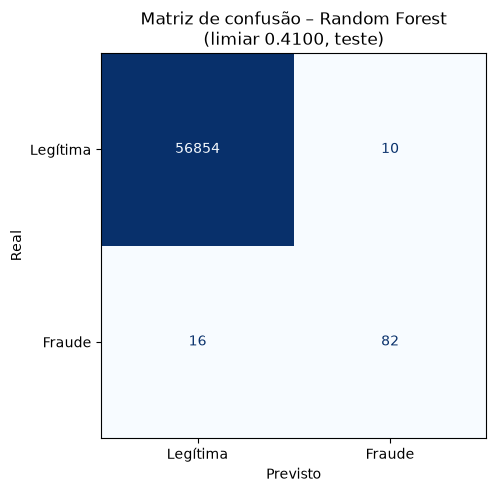

In [17]:
pred_escolhido = (proba_teste[modelo_escolhido] >= limiar_escolhido).astype(int)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_escolhido, display_labels=["Legítima", "Fraude"], cmap="Blues", values_format="d", ax=ax, colorbar=False
)
ax.set_title(f"Matriz de confusão – {modelo_escolhido}\n(limiar {limiar_escolhido:.4f}, teste)")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
plt.show()

**Conclusões da avaliação**

- **A logística com limiar 0,5 tem o maior recall (0,9082), mas precisão de 0,0612**: cerca de 1.365 transações legítimas seriam marcadas como fraude para pegar 89 fraudes. Ajustar o limiar corrige isso (precisão 0,8316, recall 0,8061).
- Pela ROC os três modelos parecem equivalentes (AUC entre 0,96 e 0,97). A curva **precisão-recall** separa melhor: AP de **0,87 (XGBoost)**, **0,84 (Random Forest)** e **0,70 (logística)**.
- Com o limiar ajustado, o **Random Forest tem o maior recall da fraude (0,8367)**, com precisão de 0,8913 e F1 de 0,8632. No XGBoost o limiar alto (0,927) trocou recall por precisão: recall de 0,7959 e precisão de 0,9398.
- **Modelo escolhido: Random Forest com limiar 0,41.** No teste ele encontrou **82 das 98 fraudes**, deixou passar 16 e gerou **10 falsos alarmes** em 56.864 transações legítimas.

## 5. Explique

Primeiro, a importância global das variáveis segundo o próprio modelo; depois, o SHAP, que mostra
**quanto cada variável empurrou a previsão** para fraude ou para legítima.

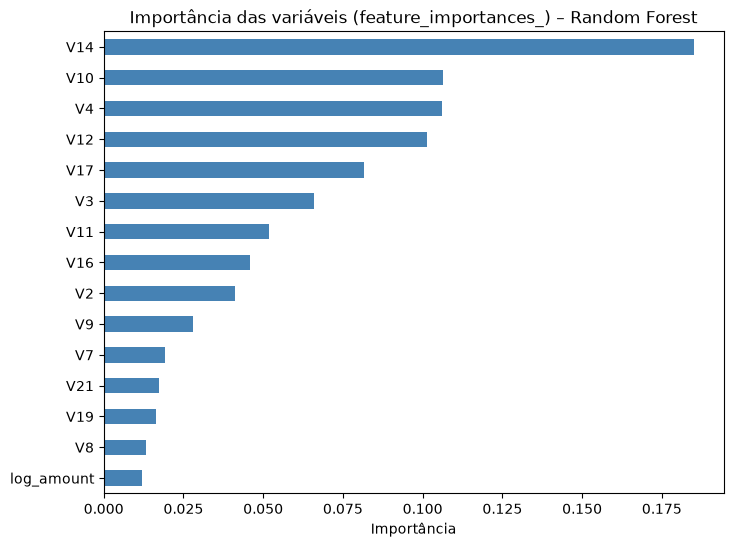

V14           0.1851
V10           0.1065
V4            0.1060
V12           0.1014
V17           0.0817
V3            0.0658
V11           0.0517
V16           0.0458
V2            0.0412
V9            0.0280
V7            0.0191
V21           0.0174
V19           0.0163
V8            0.0132
log_amount    0.0120
dtype: float64

In [18]:
modelo = modelos[modelo_escolhido]
eh_arvore = hasattr(modelo, "feature_importances_")

if eh_arvore:
    importancias = pd.Series(modelo.feature_importances_, index=features)
    titulo = f"Importância das variáveis (feature_importances_) – {modelo_escolhido}"
else:
    importancias = pd.Series(np.abs(modelo.coef_[0]), index=features)
    titulo = f"|Coeficientes| – {modelo_escolhido}"

top15 = importancias.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top15.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title(titulo)
ax.set_xlabel("Importância")
plt.show()
top15.round(4)

### SHAP

Para o SHAP rodar rápido usamos uma **amostra de 2.000 transações do teste**: todas as fraudes do teste mais
transações legítimas sorteadas. Os valores das variáveis estão padronizados (saída do `StandardScaler`).

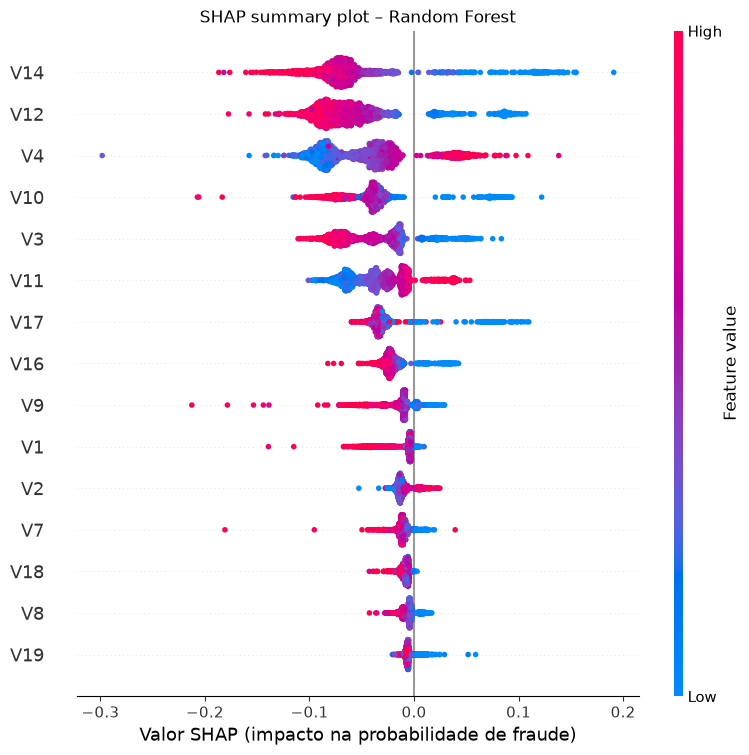

In [19]:
if eh_arvore:
    fraudes_teste = X_test[y_test == 1]
    legitimas = X_test[y_test == 0].sample(2000 - len(fraudes_teste), random_state=42)
    amostra = pd.concat([fraudes_teste, legitimas])

    explainer = shap.TreeExplainer(modelo)
    explicacao = explainer(amostra)
    if explicacao.values.ndim == 3:  # Random Forest devolve uma saída por classe
        explicacao = explicacao[:, :, 1]

    shap.summary_plot(explicacao.values, amostra, max_display=15, show=False)
    plt.title(f"SHAP summary plot – {modelo_escolhido}")
    plt.xlabel("Valor SHAP (impacto na probabilidade de fraude)")
    plt.show()
else:
    print("O modelo escolhido não é de árvore: TreeExplainer não se aplica.")

Transação 77348 | Class real = 1 | probabilidade de fraude = 1.0000


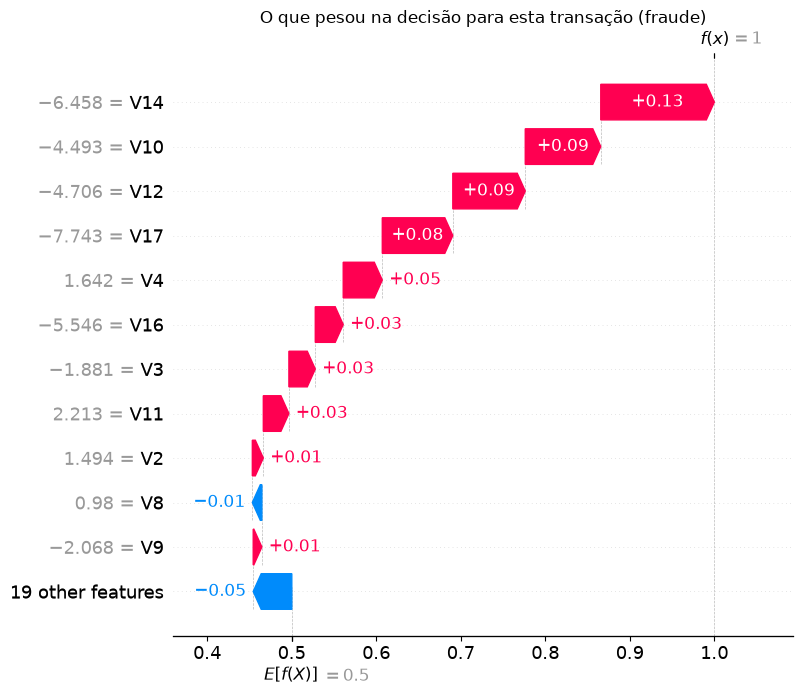

In [20]:
if eh_arvore:
    proba_amostra = modelo.predict_proba(amostra)[:, 1]
    marcadas = np.where((y_test.loc[amostra.index].values == 1) & (proba_amostra >= limiar_escolhido))[0]
    i = marcadas[0]
    print(f"Transação {amostra.index[i]} | Class real = 1 | probabilidade de fraude = {proba_amostra[i]:.4f}")

    shap.plots.waterfall(explicacao[i], max_display=12, show=False)
    plt.title("O que pesou na decisão para esta transação (fraude)")
    plt.show()

**Conclusões da explicação**

- As variáveis mais importantes do Random Forest são **V14, V10, V4, V12 e V17**.
- O SHAP confirma isso e mostra a **direção** do efeito: valores **baixos** de V14, V12, V10, V3, V17 e V16 empurram para fraude, e valores **altos** de V4 e V11 também.
- Na transação de fraude analisada, as variáveis que mais pesaram na decisão foram, nesta ordem: **V14, V10, V12, V17 e V4**.
- Como V1–V28 são componentes de PCA, sabemos *quais* componentes pesam, mas não o significado de negócio de cada um.